# Robustness check: number of broadband terms

**Question.** Do the Full and Filament fits depend on the broadband polynomial? The baseline is
$a_0 + a_1(100/s) + a_2(100/s)^2$ (Xu+12 "poly3"). Here it is compared with two extended versions, adding higher inverse powers, and one reduced version without a₂:

| model | broadband | `BROADBAND_POWERS` |
|---|---|---|
| **baseline** | $a_0 + a_1(100/s) + a_2(100/s)^2$ | `(0, -1, -2)` |
| **+ (100/s)³** | baseline $+\,a_3(100/s)^3$ | `(0, -1, -2, -3)` |
| **+ (100/s)³,⁴** | baseline $+\,a_3(100/s)^3 + a_4(100/s)^4$ | `(0, -1, -2, -3, -4)` |
| **no (100/s)²** | $a_0 + a_1(100/s)$ | `(0, -1)` |

Everything else uses the machinery of `notebooks/final/bao_fitting.ipynb`: Gaussian covariance from the measured
P(k), Σ ~ N(theory, 2) for α, and a flat Σ prior for the Σ fit. The samples, fit range and number of mocks are set in
the next cell (`samples`, `pk_file`, `SETTINGS`), and the run configuration is printed below it. The no-wiggle model also
gets the same terms, so Δχ²_det still compares like with like. Each term added or removed changes the degrees of
freedom by one.

**How to read it (decide before looking):** the baseline is robust if every shift in α is well inside its
error. Take |Δα| < 0.25 σ_α as a working threshold, and require that Δα(Fil − Full) stays the same within its error.
If a χ² drops by much more than the number of extra parameters (1 or 2), the data prefer more broadband freedom;
if it rises by much more than 1 without a₂, the data need a₂.

Nothing in `src/` is changed: the notebook sets `bao_fitting.BROADBAND_POWERS` for each model
and restores the baseline at the end.

In [1]:
import os, sys, io, contextlib
REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import numpy as np
import matplotlib.pyplot as plt
import bao_fitting as bf

MONO = os.path.join(REPO, 'data', 'processed', 'monopoles', 'box')
PK = os.path.join(REPO, 'data', 'processed', 'pk', 'box')

binsep = 2.5
base = os.path.join(MONO, f'mag=-20.8_sep=5.0-150.0_binsep={binsep:.1f}_')
samples = {
    'Full':     base + 'full.npz',
    'Filament': base + '0.0leqd_mathrmfilleq3.0.npz',
}
pk_file = os.path.join(PK, 'pk_XISMU_box_mag-20.8_dist_fil.npz')

MODELS = {                      # label -> powers of (s/100)
    'baseline':   (0, -1, -2),
    '+ (100/s)^3': (0, -1, -2, -3),
    '+ (100/s)^3,4': (0, -1, -2, -3, -4),
    'no (100/s)^2': (0, -1),
}
SETTINGS = dict(fit_range=(50, 150), n_mock=700)   # fit range [h^-1 Mpc] and number of no-wiggle mocks
N_MOCK_DIFF = 400
BASELINE = bf.BROADBAND_POWERS
assert BASELINE == MODELS['baseline'], "src/bao_fitting.py baseline changed: update MODELS"

# run configuration (everything the markdown cells refer to)
from IPython.display import Markdown, display
_s = bf.load_monopole(samples['Full'])[0]
FR = SETTINGS['fit_range']
N_FIT = int(((_s >= FR[0]) & (_s <= FR[1])).sum())
display(Markdown(
    f"**This run:** fit range {FR[0]:g}–{FR[1]:g} $h^{{-1}}$Mpc ({N_FIT} bins of {binsep:g}); "
    f"{SETTINGS['n_mock']} no-wiggle mocks per fit (p resolution 1/{SETTINGS['n_mock']}); "
    f"{N_MOCK_DIFF} correlated mocks for Fil − Full.  \n"
    f"Monopoles: `{os.path.basename(base)}*`; spectra: `{os.path.basename(pk_file)}`."))


**This run:** fit range 50–150 $h^{-1}$Mpc (40 bins of 2.5); 700 no-wiggle mocks per fit (p resolution 1/700); 400 correlated mocks for Fil − Full.  
Monopoles: `mag=-20.8_sep=5.0-150.0_binsep=2.5_*`; spectra: `pk_XISMU_box_mag-20.8_dist_fil.npz`.

## Fits
One `analyse_sample` per (model, sample), plus the Fil − Full difference test. The template and spectra are
built once, because they do not depend on the broadband. The long per-sample printouts are kept in `logs[model]`;
`print(logs['baseline'])` shows one.

In [2]:
lin = bf.linear_theory()
k, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k, P_w, P_nw, lin)
spec = bf.load_spectra(pk_file)

res, diff, logs = {}, {}, {}
try:
    for mlab, powers in MODELS.items():
        bf.BROADBAND_POWERS = powers          # read by broadband_columns() at every call
        buf = io.StringIO()
        with contextlib.redirect_stdout(buf):
            res[mlab] = {lab: bf.analyse_sample(f, spec, label=lab, T=T, lin=lin, plot=False, **SETTINGS)
                         for lab, f in samples.items()}
            diff[mlab] = {key: bf.difference_test(res[mlab], [('Filament', 'Full')], n_mock=N_MOCK_DIFF, key=key)[0][0]
                          for key in ('fit', 'fit_free')}
        logs[mlab] = buf.getvalue()
        print(f"{mlab:<12} done   n_params(linear) = {res[mlab]['Full']['fit']['X_best'].shape[1]}")
finally:
    bf.BROADBAND_POWERS = BASELINE            # never leave the module in a non-baseline state

# warnings printed by analyse_sample (e.g. unstable bias, n_gal mismatch) are not hidden
for mlab, txt in logs.items():
    for line in txt.splitlines():
        if 'WARNING' in line:
            print(mlab, '|', line)


baseline     done   n_params(linear) = 4


+ (100/s)^3  done   n_params(linear) = 5


+ (100/s)^3,4 done   n_params(linear) = 6


no (100/s)^2 done   n_params(linear) = 3


## Table
α from the α fit (profile best fit; ± is the marginal posterior std, as in the main summary). Σ is the
marginal mean ± std of the flat-prior fit. **Δα/σ** is the shift from the baseline in units of the baseline σ_α.
**Δχ²** is χ²_min(model) − χ²_min(baseline) for the α fit; noise alone changes it by about 1 per parameter
added or removed: a drop of ~1 for `+ (100/s)^3`, ~2 for `+ (100/s)^3,4`, a rise of ~1 for `no (100/s)^2`.

**Detection significance** (last three columns). Δχ²_det = χ²(no-wiggle) − χ²(BAO), and two ways of turning it
into a number of σ:
* **√Δχ²**: the usual quick estimate (Xu+12). It is exact only if, with no BAO in the data, Δχ²_det followed a
  χ² distribution with 1 degree of freedom. Here it doesn't, for two reasons that push in opposite directions:
  searching over α inflates Δχ²_det with no BAO (√Δχ² overstates), while the Σ prior keeps the BAO model from
  reducing to the no-wiggle model, so with no BAO Δχ²_det is negative ~30% of the time (√Δχ² understates).
* **Z_mock**: the significance of the null-mock p-value (fraction of no-wiggle mocks with a larger Δχ²_det),
  converted with $Z = \Phi^{-1}(1 - p/2)$. That is the same convention as √Δχ², so the two agree when the χ²₁
  approximation holds. This is the one to quote, since the mocks include both effects. With N mocks it cannot go above $\Phi^{-1}(1 - 1/2N)$; when no
  mock exceeds the data it is printed as a lower bound, ">".

In [3]:
from scipy import stats

def z_mock(p, n):
    # Gaussian-equivalent significance of a p-value, two-sided convention (= sqrt(dchi2) for chi2 with 1 dof);
    # p = 0 -> lower bound from the number of mocks
    return f"{stats.norm.isf(p / 2):.2f}" if p > 0 else f">{stats.norm.isf(1 / (2 * n)):.2f}"

hdr = (f"{'sample':<10}{'model':<15}{'alpha':>8}{'+/-':>8}{'da/sig':>8}{'<Sigma>':>9}{'+/-':>6}"
       f"{'chi2/dof':>11}{'dchi2':>7}{'det dchi2':>10}{'sqrt':>6}{'p':>7}{'Z_mock':>8}")
print(hdr); print('-' * len(hdr))
for lab in samples:
    f0 = res['baseline'][lab]['fit']
    for mlab in MODELS:
        r = res[mlab][lab]; f, g = r['fit'], r['fit_free']
        da = (f['alpha'] - f0['alpha']) / f0['alpha_marg']['std']
        print(f"{lab:<10}{mlab:<15}{f['alpha']:>8.4f}{f['alpha_marg']['std']:>8.4f}{da:>+8.2f}"
              f"{g['Sigma_marg']['mean']:>9.2f}{g['Sigma_marg']['std']:>6.2f}"
              f"{f['chi2_min']:>7.1f}/{f['dof']:<3d}{f['chi2_min'] - f0['chi2_min']:>+7.1f}"
              f"{f['dchi2_wiggle']:>10.1f}{np.sqrt(max(f['dchi2_wiggle'], 0)):>6.2f}"
              f"{r['p_detection']:>7.3f}{z_mock(r['p_detection'], SETTINGS['n_mock']):>8}")
    print()

print("Filament - Full (correlated mocks, n = %d)" % N_MOCK_DIFF)
for mlab in MODELS:
    a = diff[mlab]['fit']['alpha']; S = diff[mlab]['fit_free']['Sigma']
    print(f"  {mlab:<15} Delta alpha = {a['obs']:+.4f} ± {a['sigma']:.4f} (z = {a['z']:+.2f})   "
          f"Delta <Sigma> = {S['obs']:+.2f} ± {S['sigma']:.2f} (z = {S['z']:+.2f})")
n = SETTINGS['n_mock']
print(f"\np = 0.000 means no no-wiggle mock exceeded the observed Delta chi2, i.e. p < 1/{n}; "
      f"Z_mock can then only be bounded: Z > {stats.norm.isf(1 / (2 * n)):.2f}.")


sample    model             alpha     +/-  da/sig  <Sigma>   +/-   chi2/dof  dchi2 det dchi2  sqrt      p  Z_mock
-----------------------------------------------------------------------------------------------------------------
Full      baseline         0.9780  0.0215   +0.00     8.80  3.80   23.0/35    +0.0      17.6  4.19  0.000   >3.19
Full      + (100/s)^3      0.9778  0.0227   -0.01     9.49  4.17   23.0/34    -0.0      15.2  3.90  0.000   >3.19
Full      + (100/s)^3,4    0.9770  0.0236   -0.05     9.91  4.15   22.9/33    -0.1      14.5  3.81  0.000   >3.19
Full      no (100/s)^2     0.9777  0.0206   -0.02     7.95  2.93   23.0/36    +0.0      17.8  4.22  0.000   >3.19

Filament  baseline         0.9811  0.0445   +0.00     8.11  4.56   31.5/35    +0.0       8.2  2.87  0.003    2.98
Filament  + (100/s)^3      0.9803  0.0482   -0.02     9.48  4.60   31.3/34    -0.3       7.7  2.77  0.011    2.53
Filament  + (100/s)^3,4    0.9662  0.0373   -0.34    10.32  4.32   28.8/33    -2.8     

### Fitted broadband coefficients (α fit, at the best grid point)
θ = (B², a₀, a₁, a₂[, a₃[, a₄]]), in the units of ξ. A large a₃ that is mostly cancelled by changes in a₁ and a₂
signals degenerate terms. This is expected for the higher inverse powers, which are strongly correlated with (100/s)²
over the fit range;
the narrower the range, the stronger the degeneracy.

In [4]:
for lab in samples:
    for mlab in MODELS:
        th = res[mlab][lab]['fit']['theta']
        names = ['B2'] + [f'a{i}' for i in range(len(th) - 1)]
        print(f"{lab:<10}{mlab:<15}" + '  '.join(f"{n}={v:+.3e}" for n, v in zip(names, th)))
    print()


Full      baseline       B2=+8.310e-01  a0=-6.707e-04  a1=+9.374e-04  a2=-1.267e-04
Full      + (100/s)^3    B2=+7.971e-01  a0=-1.208e-03  a1=+2.352e-03  a2=-1.289e-03  a3=+3.284e-04
Full      + (100/s)^3,4  B2=+8.091e-01  a0=+7.048e-04  a1=-4.398e-03  a2=+7.097e-03  a3=-4.040e-03  a4=+8.060e-04
Full      no (100/s)^2   B2=+8.067e-01  a0=-6.139e-04  a1=+7.615e-04

Filament  baseline       B2=+2.877e+00  a0=-2.315e-03  a1=+7.851e-03  a2=-5.847e-03
Filament  + (100/s)^3    B2=+3.206e+00  a0=+6.584e-03  a1=-1.604e-02  a2=+1.421e-02  a3=-5.538e-03
Filament  + (100/s)^3,4  B2=+3.993e+00  a0=+9.536e-02  a1=-3.293e-01  a2=+4.072e-01  a3=-2.138e-01  a4=+3.914e-02
Filament  no (100/s)^2   B2=+2.109e+00  a0=+1.882e-03  a1=-2.209e-03



## Monopoles with the three best fits
Top: s²ξ₀ with Gaussian errors and the BAO best fit of each model (legend: χ²_min/dof).
Middle: the difference of each model from the baseline model, in units of the data error. If the curves
overlap, the extra term is not doing anything.
Bottom: data − model for each model, in units of the data error (as in `desilike_run1.ipynb`). These use only
the diagonal of the covariance; the χ² in the legend uses the full covariance, so the two need not match
point by point. The shaded band is the fit range.

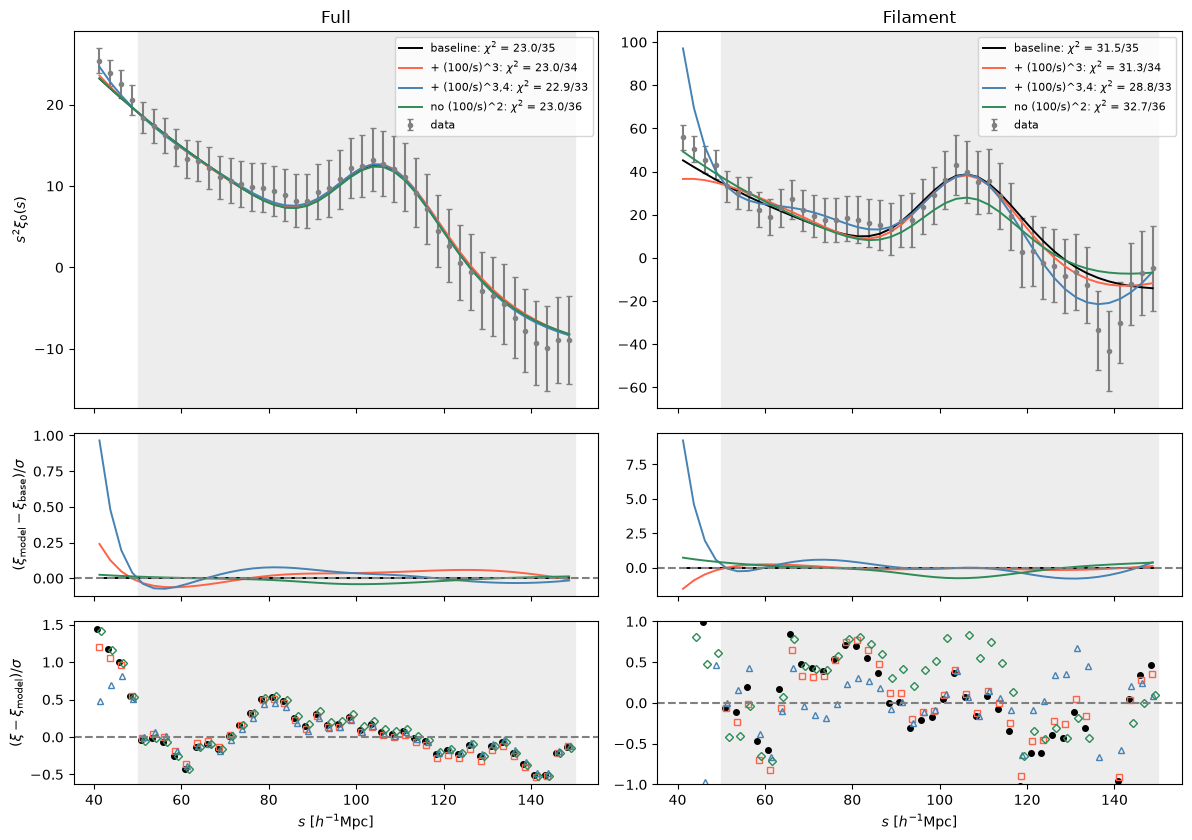

In [17]:
cols = dict(zip(MODELS, ['k', 'tomato', 'steelblue', 'seagreen', 'darkorange', 'purple']))
mks = dict(zip(MODELS, ['o', 's', '^', 'D', 'v', 'P']))
assert len(cols) == len(MODELS), 'add colours / markers for the extra models'
fig, axs = plt.subplots(3, len(samples), figsize=(6 * len(samples), 8.5), sharex=True,
                        gridspec_kw=dict(height_ratios=(3, 1.3, 1.3)), squeeze=False)
fr = SETTINGS['fit_range']
for j, lab in enumerate(samples):
    r0 = res['baseline'][lab]
    s, xi, sig = r0['s'], r0['xi'], np.sqrt(np.diag(r0['cov']))     # covariance is the same for all models
    m = (s >= fr[0] - 10) & (s <= fr[1] + 10)
    ds = 0.12 * np.median(np.diff(s))                                 # small x offsets so markers don't overlap
    axs[0, j].errorbar(s[m], (s**2 * xi)[m], yerr=(s**2 * sig)[m], fmt='.', color='gray', capsize=2, label='data')
    for k_, mlab in enumerate(MODELS):
        f, mw = res[mlab][lab]['fit'], res[mlab][lab]['model']
        axs[0, j].plot(s[m], (s**2 * mw)[m], color=cols[mlab], lw=1.4,
                       label=f"{mlab}: $\\chi^2$ = {f['chi2_min']:.1f}/{f['dof']}")
        axs[1, j].plot(s[m], ((mw - r0['model']) / sig)[m], color=cols[mlab], lw=1.4)
        axs[2, j].plot(s[m] + (k_ - (len(MODELS) - 1) / 2) * ds, ((xi - mw) / sig)[m], mks[mlab], ms=4, color=cols[mlab],
                       mfc=cols[mlab] if mlab == 'baseline' else 'none')
    for ax in axs[:, j]:
        ax.axvspan(fr[0], fr[1], color='0.93', zorder=-1)
    axs[0, j].set_title(lab); axs[0, j].legend(fontsize=8)
    axs[1, j].axhline(0, color='gray', ls='--')
    axs[2, j].axhline(0, color='gray', ls='--')
    axs[2, j].set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
axs[0, 0].set_ylabel(r'$s^2\xi_0(s)$')
axs[1, 0].set_ylabel(r'$(\xi_{\rm model}-\xi_{\rm base})/\sigma$')
axs[2, 0].set_ylabel(r'$(\xi-\xi_{\rm model})/\sigma$')
axs[2, 1].set_ylim(-1, 1)
fig.tight_layout(); plt.show()


## α: profile χ² and marginal posterior (α fit, Σ ~ N(theory, 2))
This shows directly whether the extra term moves α or only widens its distribution.

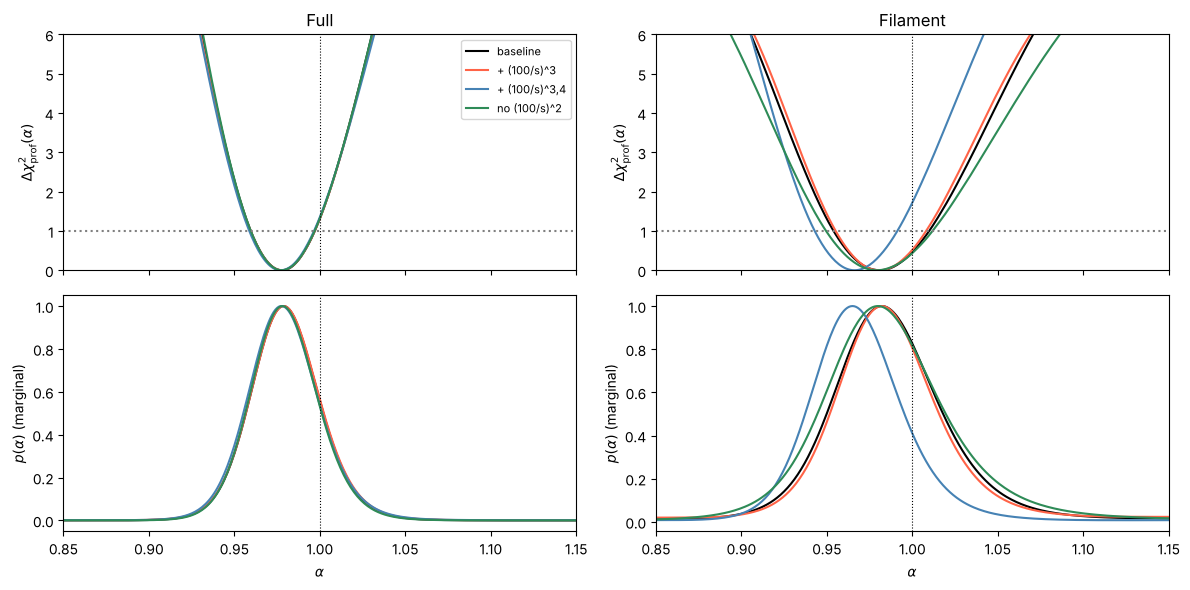

In [6]:
fig, axs = plt.subplots(2, len(samples), figsize=(6 * len(samples), 6), sharex='col')
for j, lab in enumerate(samples):
    for mlab in MODELS:
        f = res[mlab][lab]['fit']
        axs[0, j].plot(f['alpha_grid'], f['prof_alpha'] - f['prof_alpha'].min(), color=cols[mlab], label=mlab)
        axs[1, j].plot(f['alpha_grid'], f['post_alpha'] / f['post_alpha'].max(), color=cols[mlab])
    axs[0, j].axhline(1, color='gray', ls=':'); axs[0, j].set_ylim(0, 6)
    axs[0, j].set_title(lab); axs[0, j].set_ylabel(r'$\Delta\chi^2_{\rm prof}(\alpha)$')
    axs[1, j].set_ylabel(r'$p(\alpha)$ (marginal)'); axs[1, j].set_xlabel(r'$\alpha$')
    axs[1, j].set_xlim(0.85, 1.15)
    for ax in axs[:, j]:
        ax.axvline(1, color='k', ls=':', lw=0.8)
axs[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()


## (α, Σ) contours (flat-prior Σ fit), 68 / 95 %

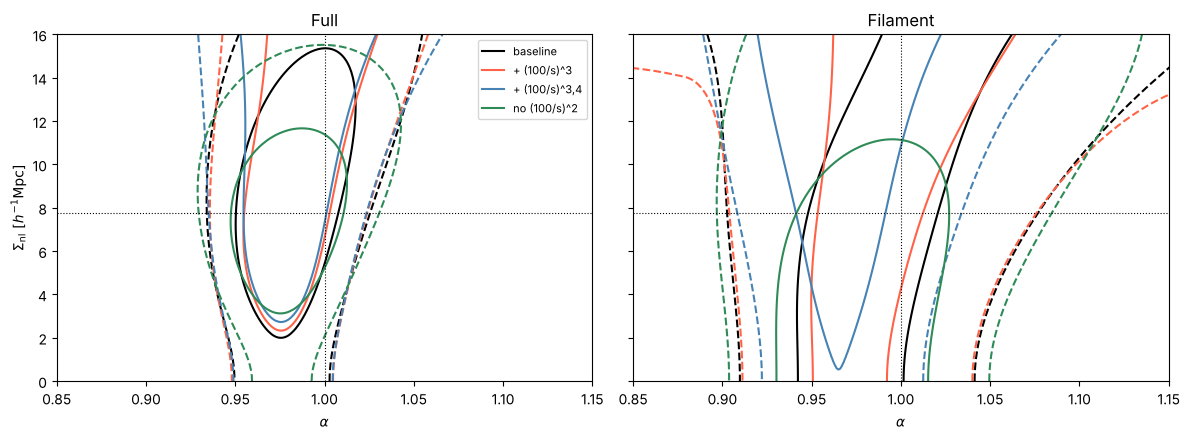

In [7]:
fig, axs = plt.subplots(1, len(samples), figsize=(6 * len(samples), 4.5), sharey=True)
th_S = res['baseline']['Full']['theory']['Sigma_mono']
for j, lab in enumerate(samples):
    ax = axs[j]
    for mlab in MODELS:
        g = res[mlab][lab]['fit_free']
        ax.contour(g['alpha_grid'], g['Sigma_grid'], g['post2d'].T, levels=bf._levels_2d(g['post2d']),
                   colors=cols[mlab], linestyles=('--', '-'))
        ax.plot([], [], color=cols[mlab], label=mlab)
    ax.axhline(th_S, color='k', ls=':', lw=0.8); ax.axvline(1, color='k', ls=':', lw=0.8)
    ax.set_title(lab); ax.set_xlabel(r'$\alpha$'); ax.set_xlim(0.85, 1.15)
axs[0].set_ylabel(r'$\Sigma_{\rm nl}\ [h^{-1}{\rm Mpc}]$'); axs[0].legend(fontsize=8)
fig.tight_layout(); plt.show()


## Notes
- `(100/s)^3` and `(100/s)^2` are strongly correlated over the fit range, so expect large, opposite a₂ and a₃
  coefficients and a widened α posterior rather than a shifted best fit.
- `(100/s)^3,4` adds two terms that fall off fast with s, so the extra freedom sits mainly at the low-s end of
  the fit range. They are strongly correlated with each other and with (100/s)², so expect large, cancelling
  coefficients and wider errors.
- `no (100/s)^2` is the opposite test: less freedom. If α holds without a₂, the baseline is not relying on the
  broadband to fit the peak; a large χ² rise means a₂ is needed to describe the shape.
- The detection p-values come from `SETTINGS['n_mock']` no-wiggle mocks: p = 0.000 means no mock exceeded,
  i.e. p < 1/n_mock (the resolution is printed in the run configuration at the top). Mocks can only measure
  Z_mock up to about Φ⁻¹(1 − 1/2N): 3.2σ for 700 mocks, 3.9σ for 10⁴; a 4σ detection needs a few ×10⁴ mocks
  to be measured rather than bounded. A p-value set by a few mocks is also noisy: p = 2/700 has a ±70% error
  (Poisson), i.e. about ±0.3 in Z_mock, so differences between models below that are not meaningful.
